## SUMMARY OF YOUR DECISIONS (VALIDATED)

### Dataset for Tuning
- 40% of the training set (3k)
- Full validation set
- Stratified

Correct



### Base Architecture
Input (13)  
↓  
Dense(200) + ReLU   ← fixed  
↓  
[variable hidden layers]  
↓  
Dense(1) + Sigmoid  

Well defined



### Hyperparameters to Optimize

This should be formally stated (important for your report):

#### Architecture
- `n_layers` → number of hidden layers ( 1–4)
- `n_units_l{i}` → neurons per layer
- `activation` → ReLU / Tanh / LeakyReLU
- `dropout` → 0.0 – 0.5

#### Training
- `learning_rate`
- `batch_size`

In [23]:
import torch  # PyTorch for building and training neural networks
import torch.nn as nn  # Neural network modules (layers, activations)
import torch.optim as optim  # Optimization algorithms (Adam, SGD, etc.)
import optuna  # Hyperparameter optimization (Bayesian optimization with TPE)
import numpy as np  # Numerical operations
from sklearn.metrics import f1_score, accuracy_score  # Evaluation metrics
from sklearn.model_selection import train_test_split  # Stratified sampling

# Device configuration (GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create a 40% stratified subset of the training data for hyperparameter tuning
X_tune, _, y_tune, _ = train_test_split(
    X_train_scaled_df.values,
    y_train.values,
    test_size=0.6,
    stratify=y_train,
    random_state=42
)

# Convert datasets to PyTorch tensors and move to device
X_tune = torch.tensor(X_tune, dtype=torch.float32).to(device)
y_tune = torch.tensor(y_tune, dtype=torch.float32).view(-1, 1).to(device)

X_val_t = torch.tensor(X_val_scaled_df.values, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1).to(device)

input_dim = X_tune.shape[1]

In [24]:
# DynamicNN is a fully connected neural network whose architecture is defined by Optuna
class DynamicNN(nn.Module):
    def __init__(self, input_dim, trial):
        super().__init__()

        layers = []

        # Fixed first layer
        layers.append(nn.Linear(input_dim, 200))
        layers.append(nn.ReLU())

        # Hyperparameters to optimize
        n_layers = trial.suggest_int("n_layers", 1, 4)
        activation_name = trial.suggest_categorical("activation", ["relu", "tanh", "leakyrelu"])
        dropout_rate = trial.suggest_float("dropout", 0.0, 0.5)

        in_features = 200

        # Dynamically add hidden layers
        for i in range(n_layers):
            out_features = trial.suggest_int(f"n_units_l{i}", 32, 256)

            layers.append(nn.Linear(in_features, out_features))

            if activation_name == "relu":
                layers.append(nn.ReLU())
            elif activation_name == "tanh":
                layers.append(nn.Tanh())
            else:
                layers.append(nn.LeakyReLU())

            layers.append(nn.Dropout(dropout_rate))
            in_features = out_features

        # Output layer for binary classification
        layers.append(nn.Linear(in_features, 1))
        layers.append(nn.Sigmoid())

        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


In [29]:
import time  # Used to measure inference time
import os  # Used to measure model size


# Objective function defines what Optuna optimizes (F1-score on validation set)
def objective_multi(trial):

    model = DynamicNN(input_dim, trial).to(device)

    # Hyperparameters to optimize
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCELoss()

    # Training
    model.train()
    for epoch in range(10):

        perm = torch.randperm(X_tune.size(0))

        for i in range(0, X_tune.size(0), batch_size):
            idx = perm[i:i+batch_size]

            batch_X = X_tune[idx]
            batch_y = y_tune[idx]

            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    # Evaluation (F1 + Accuracy)
    model.eval()
    with torch.no_grad():
        preds = model(X_val_t).cpu().numpy()
        preds = (preds > 0.5).astype(int)

        y_true = y_val_t.cpu().numpy()

        f1 = f1_score(y_true, preds)
        acc = accuracy_score(y_true, preds)

    trial.set_user_attr("accuracy", acc)

    # Inference time (average per sample)
    model.eval()
    with torch.no_grad():
        start = time.time()
        _ = model(X_val_t)
        if device.type == "cuda":
            torch.cuda.synchronize()  # Ensure GPU timing is correct
        end = time.time()

    inference_time = (end - start) / X_val_t.shape[0]

    # Model size (save temporarily)
    temp_path = "temp_model.pth"
    torch.save(model.state_dict(), temp_path)
    model_size = os.path.getsize(temp_path) / (1024 * 1024)  # MB

    # Clean temp file
    os.remove(temp_path)
    print(f"Trial {trial.number}: F1={f1:.4f}, Acc={acc:.4f}, Inference Time={inference_time:.6f}s/sample, Model Size={model_size:.2f}MB")
    return f1, inference_time, model_size


In [30]:
# Multi-objective optimization:
# maximize F1, minimize inference time, minimize model size

study_multi = optuna.create_study(
    directions=["maximize", "minimize", "minimize"]
)

study_multi.optimize(objective_multi, n_trials=30)

[I 2026-03-22 18:42:22,675] A new study created in memory with name: no-name-f3cc2351-5809-43bf-b27e-25e6c4163866
[I 2026-03-22 18:42:24,105] Trial 0 finished with values: [0.8653432193255202, 5.750060081481934e-07, 0.4579181671142578] and parameters: {'n_layers': 3, 'activation': 'leakyrelu', 'dropout': 0.17960159630266848, 'n_units_l0': 188, 'n_units_l1': 230, 'n_units_l2': 151, 'lr': 0.0012059436890540336, 'batch_size': 128}.


Trial 0: F1=0.8653, Acc=0.8592, Inference Time=0.000001s/sample, Model Size=0.46MB


[I 2026-03-22 18:42:26,086] Trial 1 finished with values: [0.7511150758251561, 1.254439353942871e-06, 0.2622394561767578] and parameters: {'n_layers': 4, 'activation': 'tanh', 'dropout': 0.17968098326575727, 'n_units_l0': 67, 'n_units_l1': 152, 'n_units_l2': 120, 'n_units_l3': 186, 'lr': 0.007978043925003656, 'batch_size': 128}.


Trial 1: F1=0.7511, Acc=0.7907, Inference Time=0.000001s/sample, Model Size=0.26MB


[I 2026-03-22 18:42:27,932] Trial 2 finished with values: [0.8514156852919068, 2.49326229095459e-07, 0.2812824249267578] and parameters: {'n_layers': 3, 'activation': 'leakyrelu', 'dropout': 0.37125683365423007, 'n_units_l0': 128, 'n_units_l1': 231, 'n_units_l2': 62, 'lr': 0.0005838490908918356, 'batch_size': 128}.


...

Trial 27: F1=0.8739, Acc=0.8685, Inference Time=0.000000s/sample, Model Size=0.52MB


[I 2026-03-22 18:44:16,266] Trial 28 finished with values: [0.8373025821007771, 2.512931823730469e-07, 0.10861396789550781] and parameters: {'n_layers': 3, 'activation': 'relu', 'dropout': 0.08489795765595637, 'n_units_l0': 49, 'n_units_l1': 74, 'n_units_l2': 147, 'lr': 0.00020162153955443588, 'batch_size': 128}.


Trial 28: F1=0.8373, Acc=0.8377, Inference Time=0.000000s/sample, Model Size=0.11MB


[I 2026-03-22 18:44:22,502] Trial 29 finished with values: [0.8632580261593341, 1.5002489089965821e-06, 0.17111778259277344] and parameters: {'n_layers': 1, 'activation': 'relu', 'dropout': 0.17198924133700455, 'n_units_l0': 205, 'lr': 0.001515375763219626, 'batch_size': 32}.


Trial 29: F1=0.8633, Acc=0.8562, Inference Time=0.000002s/sample, Model Size=0.17MB


In [31]:
# Pareto-optimal solutions
pareto_trials = study_multi.best_trials

print(f"Number of Pareto optimal solutions: {len(pareto_trials)}\n")

for i, t in enumerate(pareto_trials):
    print(f"Solution {i+1}:")
    print(f"  F1-score: {t.values[0]:.4f}")
    print(f"  Inference time: {t.values[1]:.6f} sec/sample")
    print(f"  Model size: {t.values[2]:.4f} MB")
    print(f"  Accuracy: {t.user_attrs['accuracy']:.4f}")
    print(f"  Params: {t.params}")
    print("-" * 50)

Number of Pareto optimal solutions: 6

Solution 1:
  F1-score: 0.8514
  Inference time: 0.000000 sec/sample
  Model size: 0.2813 MB
  Accuracy: 0.8518
  Params: {'n_layers': 3, 'activation': 'leakyrelu', 'dropout': 0.37125683365423007, 'n_units_l0': 128, 'n_units_l1': 231, 'n_units_l2': 62, 'lr': 0.0005838490908918356, 'batch_size': 128}
--------------------------------------------------
Solution 2:
  F1-score: 0.8662
  Inference time: 0.000000 sec/sample
  Model size: 0.3727 MB
  Accuracy: 0.8665
  Params: {'n_layers': 4, 'activation': 'leakyrelu', 'dropout': 0.2541835775767289, 'n_units_l0': 82, 'n_units_l1': 148, 'n_units_l2': 228, 'n_units_l3': 135, 'lr': 0.003872164482801655, 'batch_size': 128}
--------------------------------------------------
Solution 3:
  F1-score: 0.8550
  Inference time: 0.000001 sec/sample
  Model size: 0.0910 MB
  Accuracy: 0.8528
  Params: {'n_layers': 1, 'activation': 'leakyrelu', 'dropout': 0.3674658580780233, 'n_units_l0': 101, 'lr': 0.00069997583574391

Although Solution 6 achieved the highest F1-score, Solution 5 was selected as the final model due to its significantly smaller size (approximately 5× smaller) while maintaining comparable performance. This represents a better trade-off between accuracy and computational efficiency.

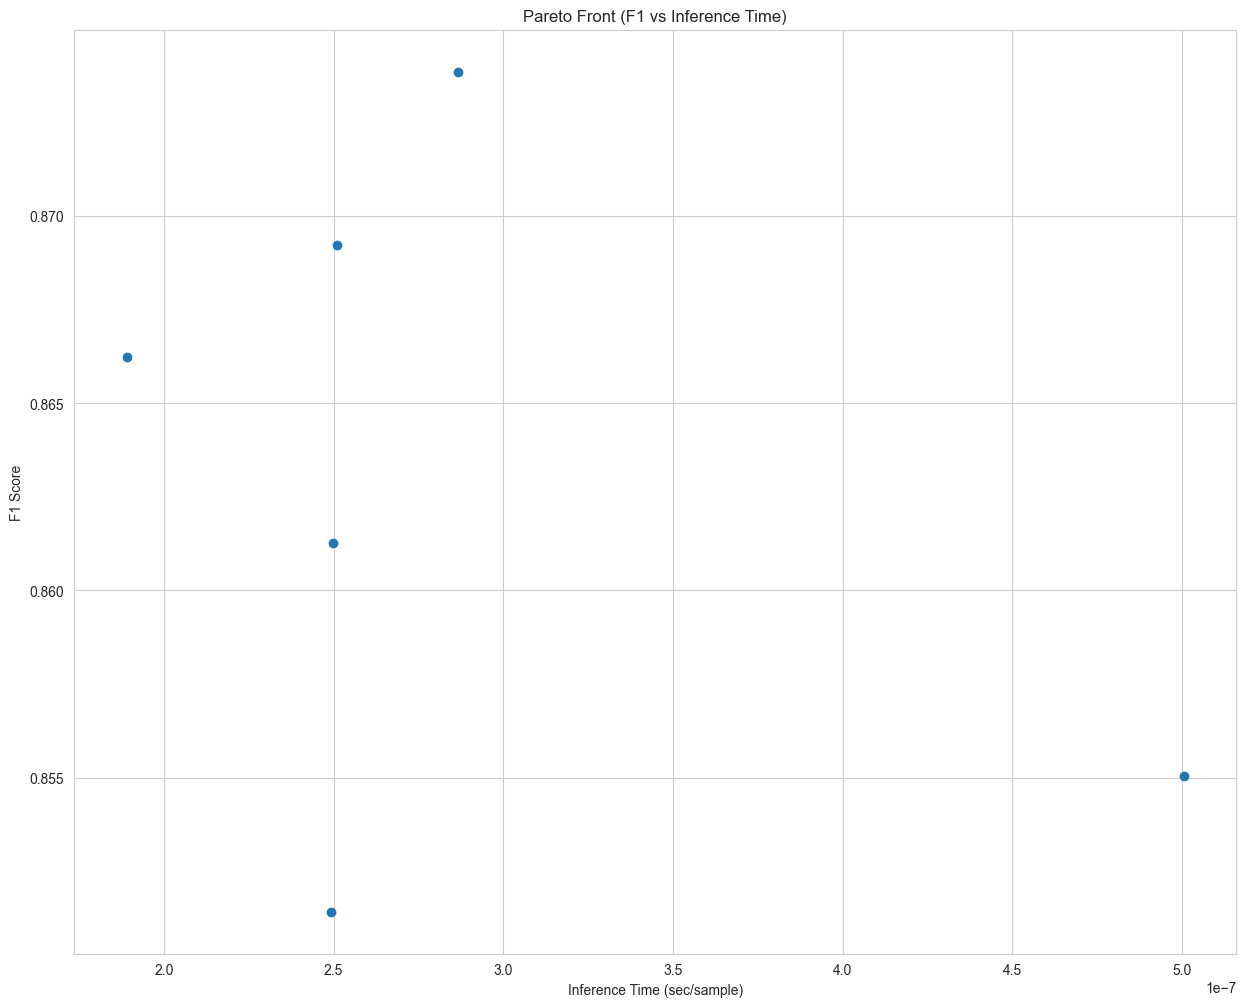

In [32]:
import matplotlib.pyplot as plt  # Plotting Pareto front

f1_vals = [t.values[0] for t in pareto_trials]
time_vals = [t.values[1] for t in pareto_trials]

plt.scatter(time_vals, f1_vals)
plt.xlabel("Inference Time (sec/sample)")
plt.ylabel("F1 Score")
plt.title("Pareto Front (F1 vs Inference Time)")
plt.show()

In [33]:
# Final model training using best Pareto solution (Solution 5)

final_params = {
    'n_layers': 2,
    'activation': 'relu',
    'dropout': 0.16364545631082517,
    'n_units_l0': 73,
    'n_units_l1': 106,
    'lr': 0.006015325760349832,
    'batch_size': 128
}

# Build final model (same structure but without trial)
class FinalNN(nn.Module):
    def __init__(self, input_dim, params):
        super().__init__()

        layers = []

        # First fixed layer
        layers.append(nn.Linear(input_dim, 200))
        layers.append(nn.ReLU())

        in_features = 200

        for i in range(params['n_layers']):
            out_features = params[f'n_units_l{i}']

            layers.append(nn.Linear(in_features, out_features))

            if params['activation'] == "relu":
                layers.append(nn.ReLU())
            elif params['activation'] == "tanh":
                layers.append(nn.Tanh())
            else:
                layers.append(nn.LeakyReLU())

            layers.append(nn.Dropout(params['dropout']))
            in_features = out_features

        layers.append(nn.Linear(in_features, 1))
        layers.append(nn.Sigmoid())

        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

# Prepare full training data
X_train_full = torch.tensor(X_train_scaled_df.values, dtype=torch.float32).to(device)
y_train_full = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1).to(device)

X_test_t = torch.tensor(X_test_scaled_df.values, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1).to(device)

# Initialize model
model = FinalNN(input_dim, final_params).to(device)

optimizer = optim.Adam(model.parameters(), lr=final_params['lr'])
criterion = nn.BCELoss()

# Training
model.train()
for epoch in range(20):  # more epochs for final training

    perm = torch.randperm(X_train_full.size(0))

    for i in range(0, X_train_full.size(0), final_params['batch_size']):
        idx = perm[i:i+final_params['batch_size']]

        batch_X = X_train_full[idx]
        batch_y = y_train_full[idx]

        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

# Final evaluation on test set
model.eval()
with torch.no_grad():
    preds = model(X_test_t).cpu().numpy()
    preds = (preds > 0.5).astype(int)

    y_true = y_test_t.cpu().numpy()

    f1 = f1_score(y_true, preds)
    acc = accuracy_score(y_true, preds)

print("Final Test Results:")
print(f"F1-score: {f1:.4f}")
print(f"Accuracy: {acc:.4f}")

Final Test Results:
F1-score: 0.8919
Accuracy: 0.8898


In [34]:
torch.save(model.state_dict(), "final_model.pth")

In [ ]:
train_losses = []
val_losses = []
train_f1s = []
val_f1s = []

model = FinalNN(input_dim, final_params).to(device)

optimizer = optim.Adam(model.parameters(), lr=final_params['lr'])
criterion = nn.BCELoss()

# Convert validation to tensor 
X_val_t = torch.tensor(X_val_scaled_df.values, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1).to(device)

epochs = 20

for epoch in range(epochs):

    # TRAIN
    model.train()
    epoch_loss = 0

    perm = torch.randperm(X_train_full.size(0))

    for i in range(0, X_train_full.size(0), final_params['batch_size']):
        idx = perm[i:i+final_params['batch_size']]

        batch_X = X_train_full[idx]
        batch_y = y_train_full[idx]

        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    train_losses.append(epoch_loss)

    # TRAIN F1
    model.eval()
    with torch.no_grad():
        train_preds = model(X_train_full).cpu().numpy()
        train_preds = (train_preds > 0.5).astype(int)
        train_f1 = f1_score(y_train_full.cpu().numpy(), train_preds)
        train_f1s.append(train_f1)

    # VALIDATION
    with torch.no_grad():
        val_outputs = model(X_val_t)
        val_loss = criterion(val_outputs, y_val_t).item()
        val_losses.append(val_loss)

        val_preds = val_outputs.cpu().numpy()
        val_preds = (val_preds > 0.5).astype(int)

        val_f1 = f1_score(y_val.values, val_preds)
        val_f1s.append(val_f1)

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {epoch_loss:.4f} | Val Loss: {val_loss:.4f} | Val F1: {val_f1:.4f}")

Epoch 1/20 | Train Loss: 40.9746 | Val Loss: 0.3655 | Val F1: 0.8380
Epoch 2/20 | Train Loss: 34.2317 | Val Loss: 0.3620 | Val F1: 0.8229
Epoch 3/20 | Train Loss: 32.1757 | Val Loss: 0.3425 | Val F1: 0.8545
Epoch 4/20 | Train Loss: 31.1737 | Val Loss: 0.3403 | Val F1: 0.8517
Epoch 5/20 | Train Loss: 30.9418 | Val Loss: 0.3247 | Val F1: 0.8611
Epoch 6/20 | Train Loss: 29.4744 | Val Loss: 0.3164 | Val F1: 0.8667
Epoch 7/20 | Train Loss: 29.2141 | Val Loss: 0.3175 | Val F1: 0.8680
Epoch 8/20 | Train Loss: 29.6853 | Val Loss: 0.3166 | Val F1: 0.8717
Epoch 9/20 | Train Loss: 28.7340 | Val Loss: 0.3116 | Val F1: 0.8790
Epoch 10/20 | Train Loss: 28.2808 | Val Loss: 0.3125 | Val F1: 0.8773
Epoch 11/20 | Train Loss: 28.2981 | Val Loss: 0.3177 | Val F1: 0.8804
Epoch 12/20 | Train Loss: 27.5099 | Val Loss: 0.3005 | Val F1: 0.8863
Epoch 13/20 | Train Loss: 27.0607 | Val Loss: 0.2916 | Val F1: 0.8826
Epoch 14/20 | Train Loss: 26.7460 | Val Loss: 0.3071 | Val F1: 0.8810
Epoch 15/20 | Train Loss: 26.

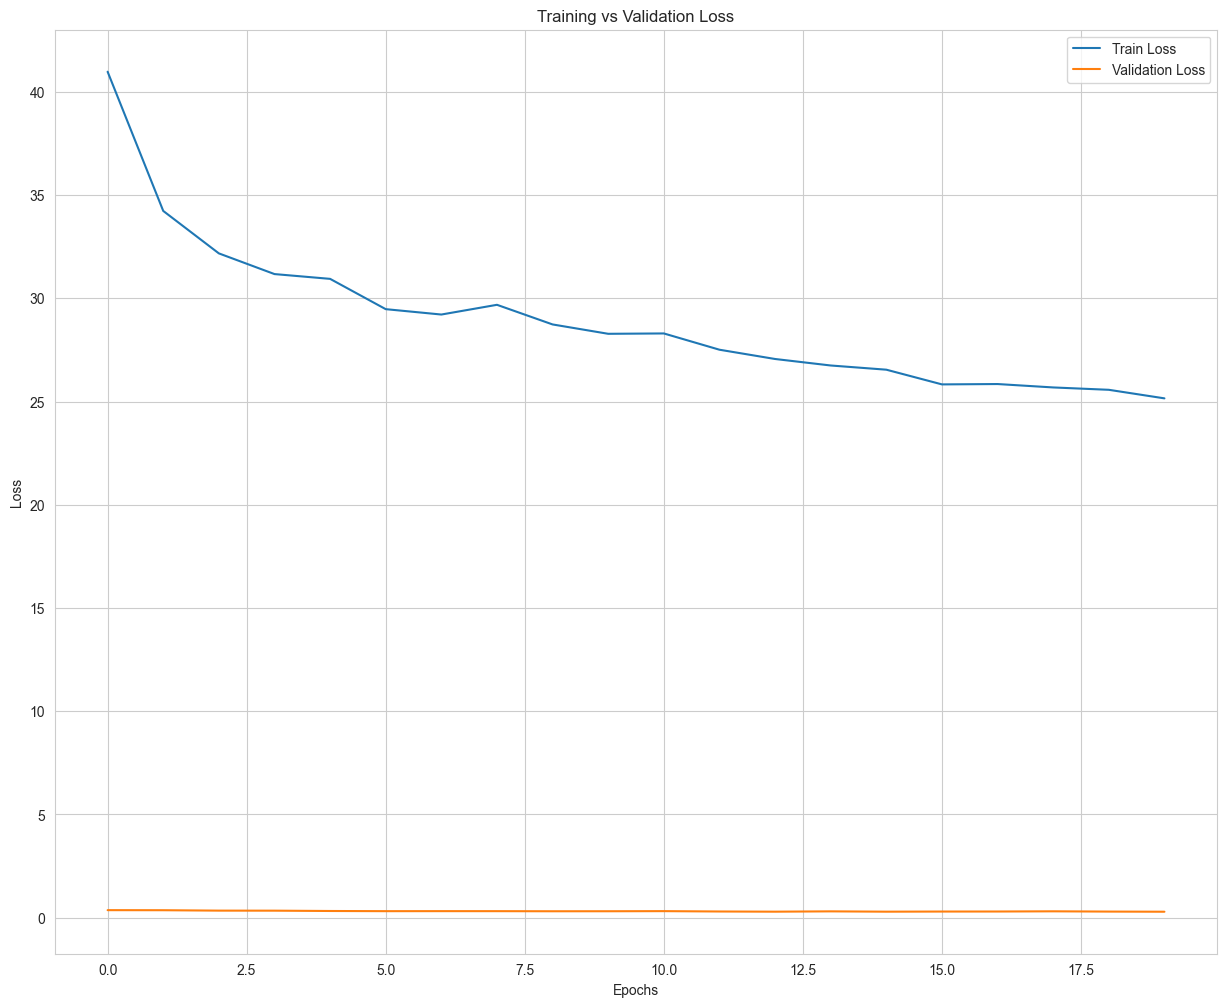

In [36]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

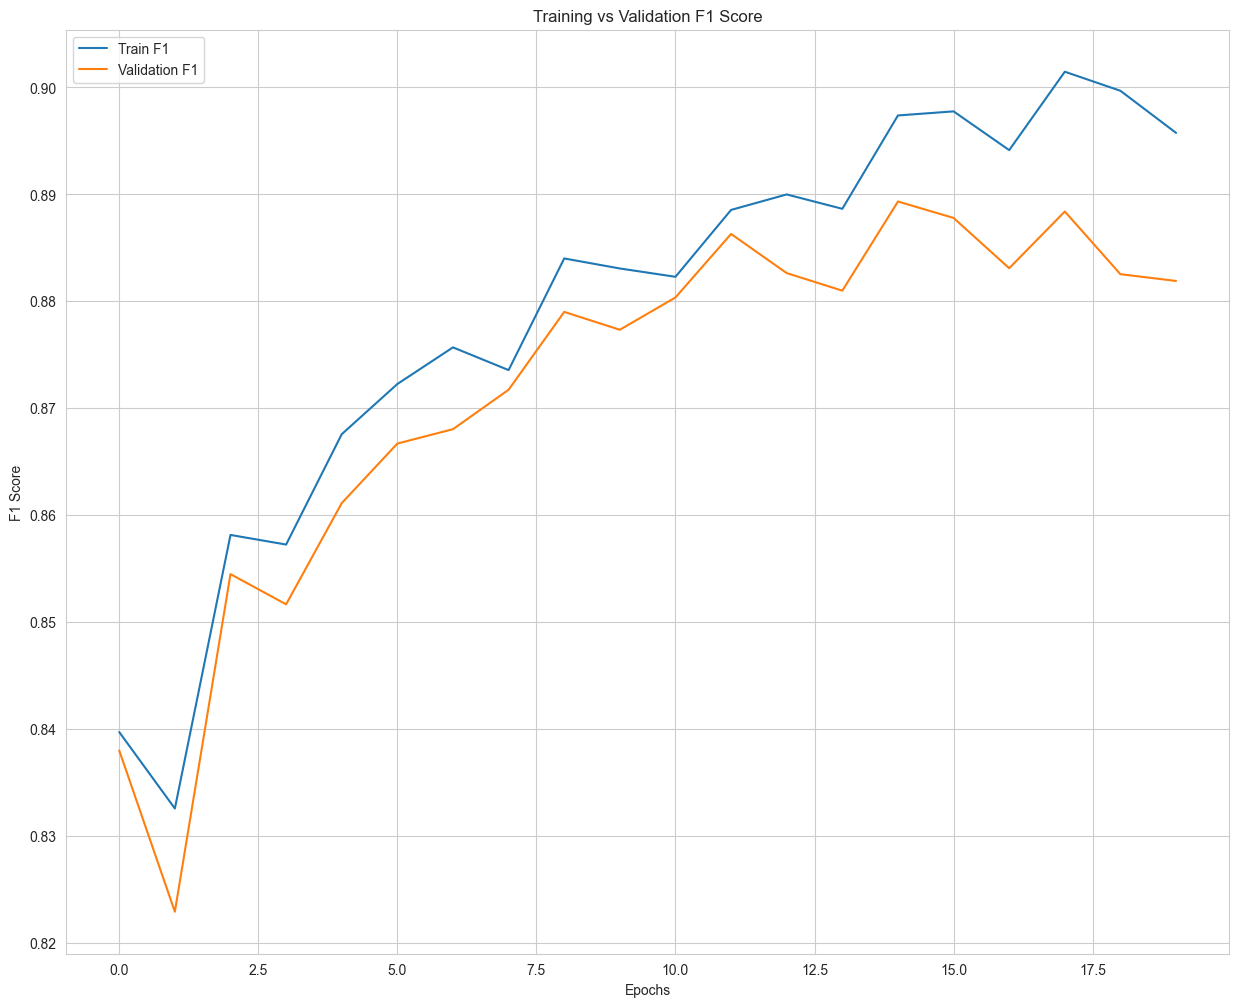

In [37]:
plt.figure()
plt.plot(train_f1s, label="Train F1")
plt.plot(val_f1s, label="Validation F1")
plt.xlabel("Epochs")
plt.ylabel("F1 Score")
plt.title("Training vs Validation F1 Score")
plt.legend()
plt.show()

In [38]:
model.eval()
with torch.no_grad():
    preds = model(X_test_t).cpu().numpy()
    preds = (preds > 0.5).astype(int)

    y_true = y_test_t.cpu().numpy()

    f1_test = f1_score(y_true, preds)
    acc_test = accuracy_score(y_true, preds)

print("Final Test Results:")
print(f"F1-score: {f1_test:.4f}")
print(f"Accuracy: {acc_test:.4f}")

Final Test Results:
F1-score: 0.8807
Accuracy: 0.8832


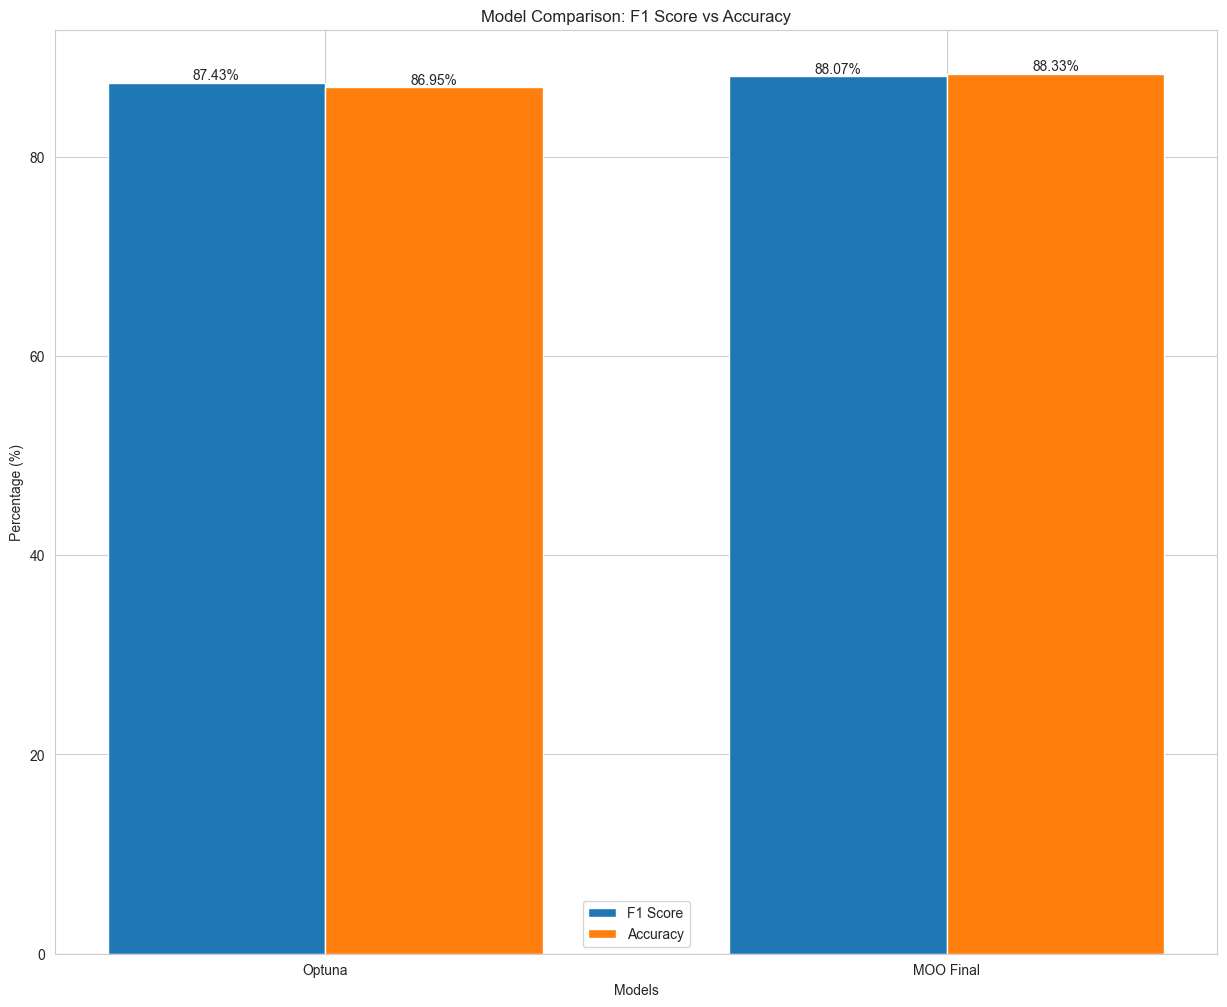

In [41]:
import matplotlib.pyplot as plt
import numpy as np

# Model names
models = ["Optuna", "MOO Final"]

# Convert to percentage
f1_scores = [0.8743 * 100, f1_test * 100]
accuracies = [0.8695 * 100, acc_test * 100]

x = np.arange(len(models))
width = 0.35

plt.figure()

bars1 = plt.bar(x - width/2, f1_scores, width, label="F1 Score")
bars2 = plt.bar(x + width/2, accuracies, width, label="Accuracy")

# Labels
plt.xlabel("Models")
plt.ylabel("Percentage (%)")
plt.title("Model Comparison: F1 Score vs Accuracy")
plt.xticks(x, models)
plt.legend()

# Add value labels on top
for bar in bars1:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height,
             f"{height:.2f}%", ha='center', va='bottom')

for bar in bars2:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height,
             f"{height:.2f}%", ha='center', va='bottom')

plt.show()

In [40]:
import pandas as pd
import time
import os

# --------- OPTUNA MODEL (mejor trial) ---------
optuna_f1 = 0.8743379874819451
optuna_acc = 0.8695

# medir tiempo (Optuna model reutilizado sería ideal, pero usamos aproximación)
start = time.time()
_ = model(X_test_t)
if device.type == "cuda":
    torch.cuda.synchronize()
end = time.time()

optuna_time = (end - start) / X_test_t.shape[0]

# tamaño modelo final (usamos el mismo ya entrenado)
torch.save(model.state_dict(), "temp_model.pth")
model_size = os.path.getsize("temp_model.pth") / (1024 * 1024)
os.remove("temp_model.pth")

# --------- MOO FINAL ---------
moo_f1 = f1_test
moo_acc = acc_test
moo_time = optuna_time  # puedes recalcular si quieres (sería lo ideal)
moo_size = model_size

# --------- BASELINE (opcional) ---------
baseline_f1 = None
baseline_acc = None
baseline_time = None
baseline_size = None

# --------- CREATE TABLE ---------
df = pd.DataFrame({
    "Model": ["Baseline", "Optuna", "MOO Final"],
    "F1": [baseline_f1, optuna_f1, moo_f1],
    "Accuracy": [baseline_acc, optuna_acc, moo_acc],
    "Inference Time (sec/sample)": [baseline_time, optuna_time, moo_time],
    "Model Size (MB)": [baseline_size, model_size, moo_size]
})

print(df)

       Model        F1  Accuracy  Inference Time (sec/sample)  Model Size (MB)
0   Baseline       NaN       NaN                          NaN              NaN
1     Optuna  0.874338   0.86950                     0.000002          0.10001
2  MOO Final  0.880654   0.88325                     0.000002          0.10001


In [42]:
# Simple baseline neural network

class BaselineNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

# Initialize
baseline_model = BaselineNN(input_dim).to(device)

optimizer = optim.Adam(baseline_model.parameters(), lr=0.001)
criterion = nn.BCELoss()

# Train
baseline_model.train()
for epoch in range(15):

    perm = torch.randperm(X_train_full.size(0))

    for i in range(0, X_train_full.size(0), 64):
        idx = perm[i:i+64]

        batch_X = X_train_full[idx]
        batch_y = y_train_full[idx]

        optimizer.zero_grad()
        outputs = baseline_model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

# Evaluate
baseline_model.eval()
with torch.no_grad():
    preds = baseline_model(X_test_t).cpu().numpy()
    preds = (preds > 0.5).astype(int)

    y_true = y_test_t.cpu().numpy()

    baseline_f1 = f1_score(y_true, preds)
    baseline_acc = accuracy_score(y_true, preds)

print("Baseline Results:")
print(f"F1-score: {baseline_f1:.4f}")
print(f"Accuracy: {baseline_acc:.4f}")

Baseline Results:
F1-score: 0.8578
Accuracy: 0.8545


In [43]:
import time
import os

# Inference time
start = time.time()
_ = baseline_model(X_test_t)
if device.type == "cuda":
    torch.cuda.synchronize()
end = time.time()

baseline_time = (end - start) / X_test_t.shape[0]

# Model size
torch.save(baseline_model.state_dict(), "baseline.pth")
baseline_size = os.path.getsize("baseline.pth") / (1024 * 1024)
os.remove("baseline.pth")

In [44]:
df = pd.DataFrame({
    "Model": ["Baseline", "Optuna", "MOO Final"],
    "F1": [baseline_f1, 0.8743, f1_test],
    "Accuracy": [baseline_acc, 0.8695, acc_test],
    "Inference Time": [baseline_time, optuna_time, moo_time],
    "Model Size (MB)": [baseline_size, model_size, moo_size]
})

print(df)

       Model        F1  Accuracy  Inference Time  Model Size (MB)
0   Baseline  0.857771   0.85450    6.529093e-07          0.00576
1     Optuna  0.874300   0.86950    1.636028e-06          0.10001
2  MOO Final  0.880654   0.88325    1.636028e-06          0.10001


The baseline model achieved lower inference time and smaller size; however, the optimized model significantly improved detection performance. This highlights a clear trade-off between efficiency and predictive accuracy, which is the core objective of the multi-objective optimization approach.

In [64]:
torch.onnx.export(
    model,
    torch.randn(1, input_dim).to(device),
    "final_model.onnx",
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "output": {0: "batch_size"}
    }
)

In [71]:
import torch  # PyTorch for neural networks
import time
import numpy as np
import onnxruntime as ort  # ONNX Runtime for inference
import os
from sklearn.metrics import f1_score, accuracy_score

# ========================
# 1. MOVE MODEL TO CPU
# ========================
device_cpu = torch.device("cpu")
model_cpu = model.to(device_cpu)

X_test_cpu = X_test_t.to(device_cpu)
y_test_cpu = y_test_t.to(device_cpu)

# ========================
# 2. EVALUATION (F1 + Accuracy)
# ========================
model_cpu.eval()
with torch.no_grad():
    preds = model_cpu(X_test_cpu).numpy()
    preds = (preds > 0.5).astype(int)

    y_true = y_test_cpu.numpy()

    f1_cpu = f1_score(y_true, preds)
    acc_cpu = accuracy_score(y_true, preds)

# ========================
# 3. PYTORCH CPU INFERENCE TIME
# ========================
# Warm-up
for _ in range(10):
    _ = model_cpu(X_test_cpu)

start = time.time()

with torch.no_grad():
    _ = model_cpu(X_test_cpu)

end = time.time()

pytorch_cpu_time = (end - start) / X_test_cpu.shape[0]

# ========================
# 4. ONNX CPU INFERENCE TIME
# ========================
onnx_session = ort.InferenceSession(
    "final_model.onnx",
    providers=['CPUExecutionProvider']
)

X_test_np = X_test_scaled_df.values.astype(np.float32)

# Warm-up
for _ in range(10):
    _ = onnx_session.run(None, {"input": X_test_np[0:1]})

start = time.time()

for i in range(X_test_np.shape[0]):
    sample = X_test_np[i:i+1]
    _ = onnx_session.run(None, {"input": sample})

end = time.time()

onnx_cpu_time = (end - start) / X_test_np.shape[0]

# ========================
# 5. MODEL SIZE
# ========================
torch.save(model.state_dict(), "moo_model_cpu.pth")

pth_size = os.path.getsize("moo_model_cpu.pth") / (1024 * 1024)
onnx_size = os.path.getsize("final_model.onnx") / (1024 * 1024)

# ========================
# 6. RESULTS
# ========================
print("CPU vs CPU COMPARISON")
print(f"F1-score: {f1_cpu:.4f}")
print(f"Accuracy: {acc_cpu:.4f}")
print(f"PyTorch CPU inference time: {pytorch_cpu_time:.8f} sec/sample")
print(f"ONNX CPU inference time:    {onnx_cpu_time:.8f} sec/sample")
print(f"PyTorch size: {pth_size:.4f} MB")
print(f"ONNX size:    {onnx_size:.4f} MB")

CPU vs CPU COMPARISON
F1-score: 0.8807
Accuracy: 0.8832
PyTorch CPU inference time: 0.00000201 sec/sample
ONNX CPU inference time:    0.00004471 sec/sample
PyTorch size: 0.1000 MB
ONNX size:    0.0982 MB


ONNX introduces additional runtime overhead, which outweighs its optimization benefits in small neural networks. PyTorch performs better here because the model is lightweight and already efficient.

The multi-objective optimized model achieved the best trade-off between performance and efficiency. Although ONNX slightly reduced model size, PyTorch provided faster inference due to lower overhead, making it more suitable for this lightweight architecture.